In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/hotel_bookings.csv')

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

### What factors are associated with hotel booking cancellations, and can we predict whether a booking will be canceled?

## Understand the data

In [5]:
df.shape

(119390, 32)

In [6]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [7]:
df.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [8]:
(df.isna().sum() / len(df) * 100).round(2)

hotel                              0.00
is_canceled                        0.00
lead_time                          0.00
arrival_date_year                  0.00
arrival_date_month                 0.00
arrival_date_week_number           0.00
arrival_date_day_of_month          0.00
stays_in_weekend_nights            0.00
stays_in_week_nights               0.00
adults                             0.00
children                           0.00
babies                             0.00
meal                               0.00
country                            0.41
market_segment                     0.00
distribution_channel               0.00
is_repeated_guest                  0.00
previous_cancellations             0.00
previous_bookings_not_canceled     0.00
reserved_room_type                 0.00
assigned_room_type                 0.00
booking_changes                    0.00
deposit_type                       0.00
agent                             13.69
company                           94.31


In [9]:
df.duplicated().sum()

31994

In [10]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [11]:
df.nunique()

hotel                                2
is_canceled                          2
lead_time                          479
arrival_date_year                    3
arrival_date_month                  12
arrival_date_week_number            53
arrival_date_day_of_month           31
stays_in_weekend_nights             17
stays_in_week_nights                35
adults                              14
children                             5
babies                               5
meal                                 5
country                            177
market_segment                       8
distribution_channel                 5
is_repeated_guest                    2
previous_cancellations              15
previous_bookings_not_canceled      73
reserved_room_type                  10
assigned_room_type                  12
booking_changes                     21
deposit_type                         3
agent                              333
company                            352
days_in_waiting_list     

In [12]:
df['is_canceled'].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [13]:
(df['is_canceled'].value_counts(normalize=True) * 100).round(2)

is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64

## Handle duplicates

In [14]:
df.duplicated().sum()

31994

In [15]:
df = df.drop_duplicates()


In [16]:
df.shape

(87396, 32)

## Handle missing values

In [17]:
df.isna().sum()

hotel                                 0
is_canceled                           0
lead_time                             0
arrival_date_year                     0
arrival_date_month                    0
arrival_date_week_number              0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                              4
babies                                0
meal                                  0
country                             452
market_segment                        0
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
assigned_room_type                    0
booking_changes                       0
deposit_type                          0
agent                             12193
company                           82137


In [18]:
df = df.drop(columns=['company'])


In [19]:
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna(df['country'].mode()[0])
df['agent'] = df['agent'].fillna(0)

In [20]:
df[['children', 'agent']] = df[['children', 'agent']].astype(int)

In [21]:
df.isna().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces 

## Handle invalid values

In [22]:
zero_guests = (df['adults'] + df['children'] + df['babies']) == 0
zero_guests.sum()

166

In [23]:
df = df[~zero_guests]

In [24]:
df.loc[(df['adr'] < 0) | (df['adr'] > 1000), ['hotel', 'adr']]

,hotel,adr
14969,Resort Hotel,-6.38
48515,City Hotel,5400.00


In [25]:
df = df[df['adr'].between(0, 1000)]

## Remove data leakage

In [26]:
pd.crosstab(df['reservation_status'], df['is_canceled'])

is_canceled,0,1
reservation_status,,
Canceled,0,22995
Check-Out,63220,0
No-Show,0,1013


`reservation_status` directly reveals whether a booking was canceled, and `reservation_status_date` is recorded after the booking outcome. Both columns must be removed before analysis and modeling.

In [27]:
df = df.drop(columns=['reservation_status', 'reservation_status_date'])
df = df.drop_duplicates()


## Check the cleaned data

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 86943 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           86943 non-null  object 
 1   is_canceled                     86943 non-null  int64  
 2   lead_time                       86943 non-null  int64  
 3   arrival_date_year               86943 non-null  int64  
 4   arrival_date_month              86943 non-null  object 
 5   arrival_date_week_number        86943 non-null  int64  
 6   arrival_date_day_of_month       86943 non-null  int64  
 7   stays_in_weekend_nights         86943 non-null  int64  
 8   stays_in_week_nights            86943 non-null  int64  
 9   adults                          86943 non-null  int64  
 10  children                        86943 non-null  int32  
 11  babies                          86943 non-null  int64  
 12  meal                            8694

In [29]:
df.isna().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces 

In [30]:
df.duplicated().sum()

0

In [31]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000,86943.000000
mean,0.273144,79.820089,2016.210563,26.834662,15.814660,1.004762,2.624283,1.879588,0.139160,0.010881,0.038669,0.030227,0.184638,0.269142,81.110843,0.728684,106.493750,0.084584,0.700344
std,0.445577,85.954833,0.685980,13.667923,8.835197,1.027010,2.037910,0.621981,0.456667,0.113889,0.192806,0.369599,1.735848,0.711364,109.977020,9.851494,51.893858,0.282081,0.832309
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,11.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,72.250000,0.000000,0.000000
50%,0.000000,49.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,98.300000,0.000000,0.000000
75%,1.000000,125.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,0.000000,134.100000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,18.000000,535.000000,391.000000,510.000000,8.000000,5.000000


In [32]:
df.to_csv('../data/cleaned_hotel_bookings.csv', index=False)

# Exploratory Data Analysis

In [33]:
sns.set_style('whitegrid')
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

## Univariate Analysis

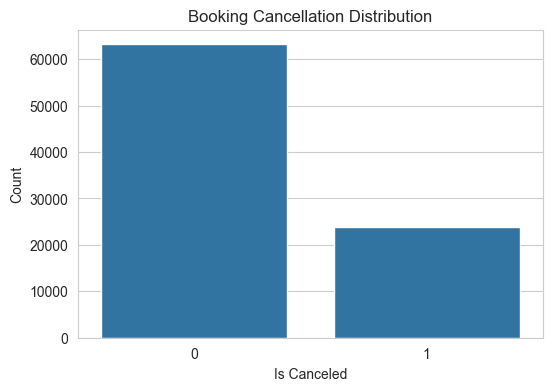

In [34]:
plt.figure(figsize=(6, 4))
sns.countplot(x='is_canceled', data=df)
plt.title('Booking Cancellation Distribution')
plt.xlabel('Is Canceled')
plt.ylabel('Count')
plt.show()

About 27.31% of the cleaned bookings were canceled. Because the classes are imbalanced, accuracy alone is not sufficient; recall, F1, and ROC-AUC are also needed to judge the model.

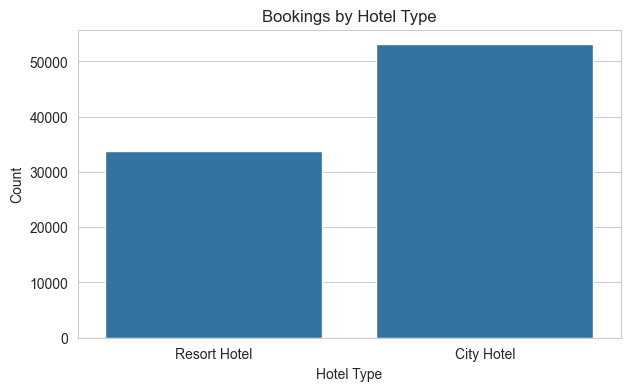

In [35]:
plt.figure(figsize=(7, 4))
sns.countplot(x='hotel', data=df)
plt.title('Bookings by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Count')
plt.show()

City Hotel contributes more bookings than Resort Hotel, so overall cancellation totals are influenced by both hotel-specific risk and the larger City Hotel booking volume.

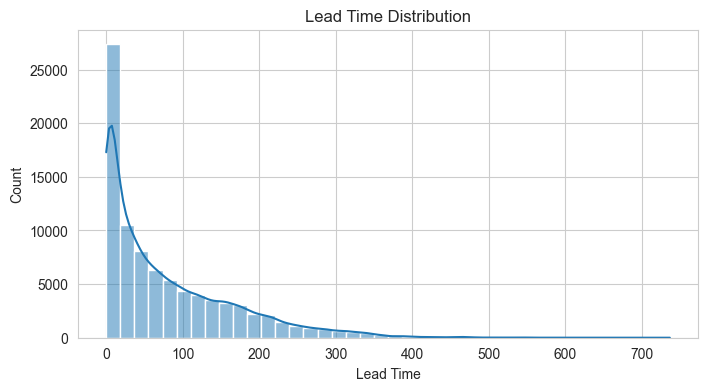

In [36]:
plt.figure(figsize=(8, 4))
sns.histplot(df['lead_time'], bins=40, kde=True)
plt.title('Lead Time Distribution')
plt.xlabel('Lead Time')
plt.ylabel('Count')
plt.show()

Lead time is strongly right-skewed: most bookings are made relatively near arrival, while a smaller set is booked far in advance. The later cancellation comparison tests whether this long tail carries additional risk.

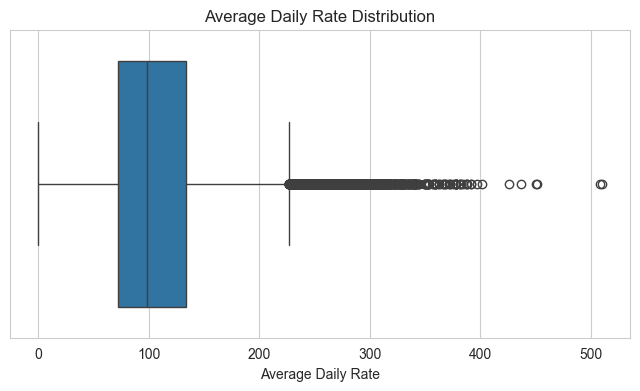

In [37]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['adr'])
plt.title('Average Daily Rate Distribution')
plt.xlabel('Average Daily Rate')
plt.show()

ADR is concentrated around typical room prices with a limited high-price tail. The invalid negative and extreme 5,400 values were removed earlier, leaving a defensible 0 to 510 range for analysis and modeling.

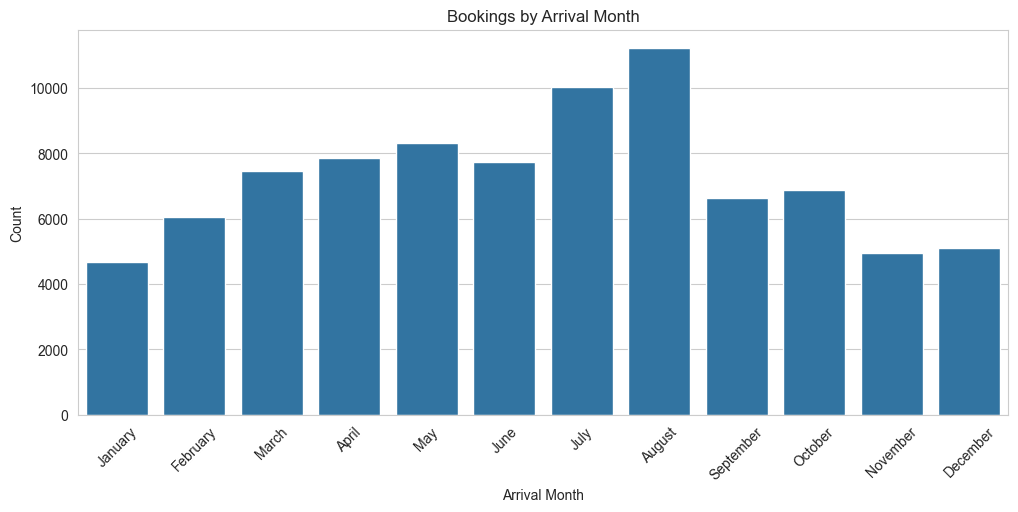

In [38]:
plt.figure(figsize=(12, 5))
sns.countplot(x='arrival_date_month', data=df, order=month_order)
plt.title('Bookings by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

Booking volume is seasonal and peaks in the summer months. This makes the later monthly cancellation-rate chart more informative than raw counts alone.

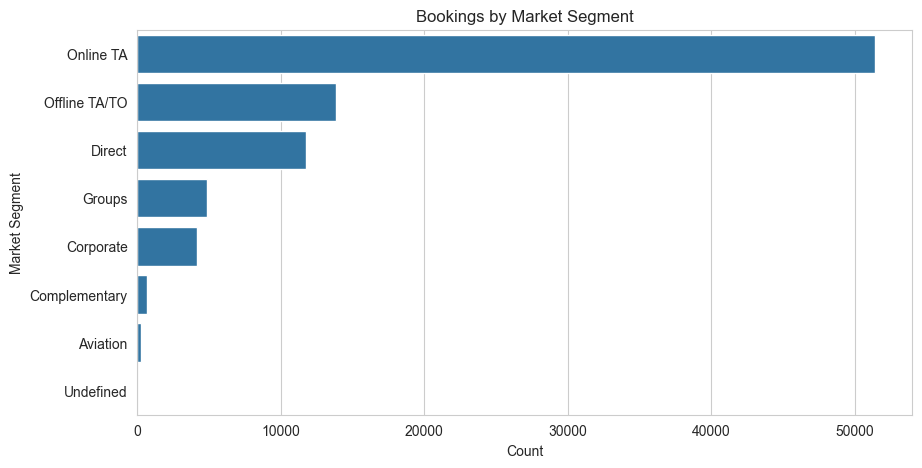

In [39]:
plt.figure(figsize=(10, 5))
sns.countplot(y='market_segment', data=df, order=df['market_segment'].value_counts().index)
plt.title('Bookings by Market Segment')
plt.xlabel('Count')
plt.ylabel('Market Segment')
plt.show()

Online TA is the dominant market segment, followed by Offline TA/TO and Direct. Segment-level cancellation rates must be read together with these very different sample sizes.

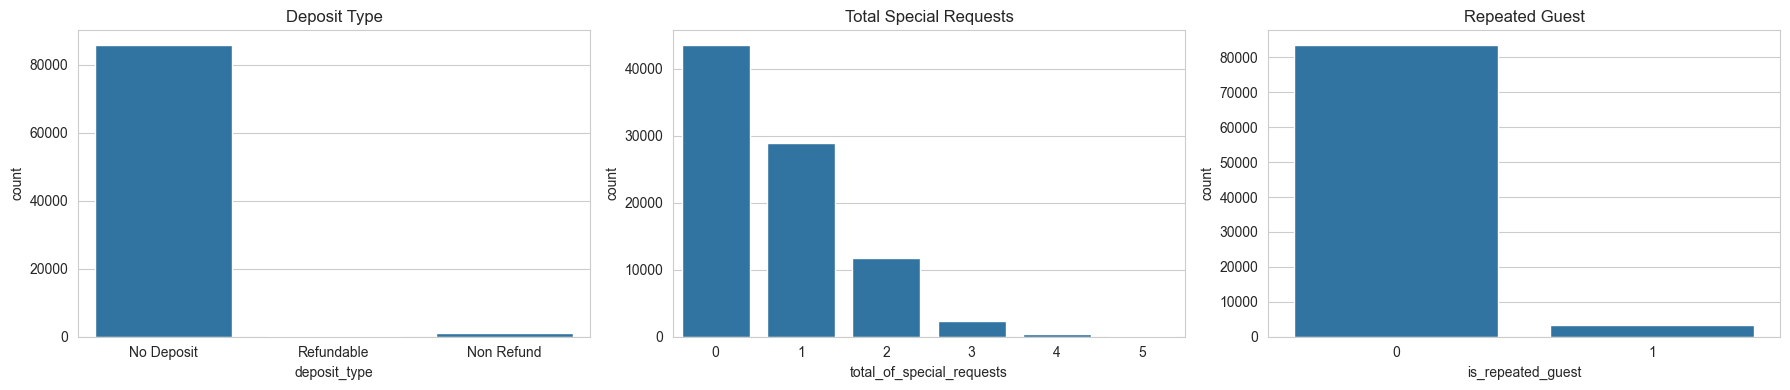

In [40]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(x='deposit_type', data=df, ax=ax[0])
ax[0].set_title('Deposit Type')
sns.countplot(x='total_of_special_requests', data=df, ax=ax[1])
ax[1].set_title('Total Special Requests')
sns.countplot(x='is_repeated_guest', data=df, ax=ax[2])
ax[2].set_title('Repeated Guest')
plt.tight_layout()
plt.show()

Most bookings have no deposit, no special requests, and come from new guests. The later rate-based charts show why the smaller non-refundable, high-request, and repeated-guest groups are still important predictive signals.

## Bivariate Analysis

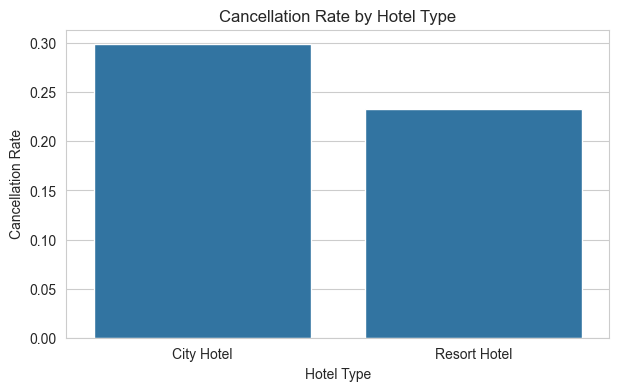

In [41]:
hotel_cancellation = (
    df.groupby('hotel')['is_canceled']
      .mean()
      .reset_index()
)
plt.figure(figsize=(7, 4))
sns.barplot(x='hotel', y='is_canceled', data=hotel_cancellation)
plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate')
plt.show()

City Hotel has a higher cancellation rate than Resort Hotel.

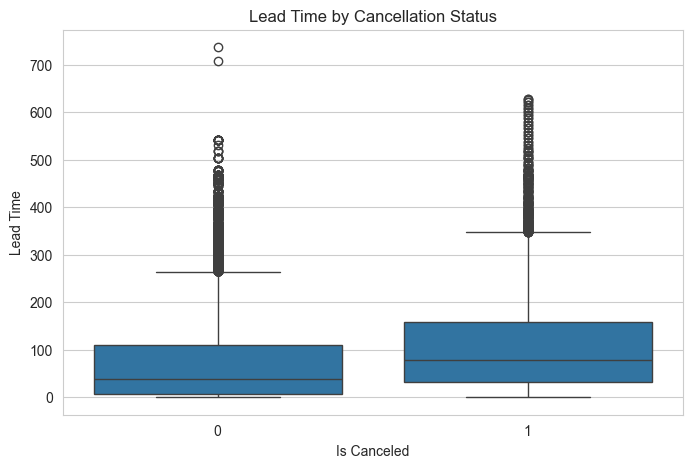

In [42]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='is_canceled', y='lead_time', data=df)
plt.title('Lead Time by Cancellation Status')
plt.xlabel('Is Canceled')
plt.ylabel('Lead Time')
plt.show()

Canceled bookings have a higher median lead time than bookings that were not canceled.

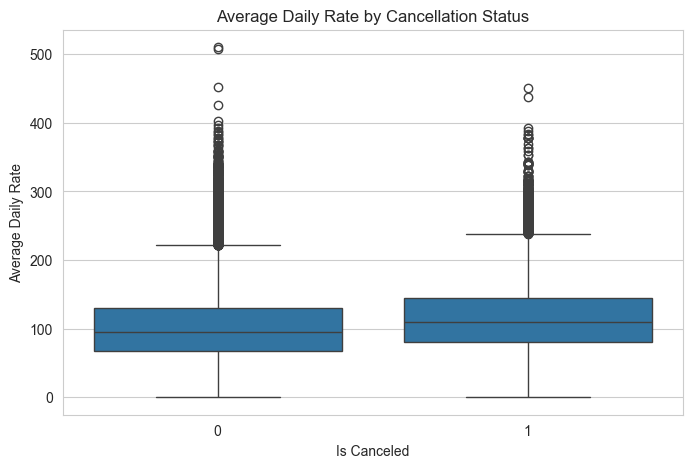

In [43]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='is_canceled', y='adr', data=df)
plt.title('Average Daily Rate by Cancellation Status')
plt.xlabel('Is Canceled')
plt.ylabel('Average Daily Rate')
plt.show()

Canceled bookings have a higher average and median daily rate.

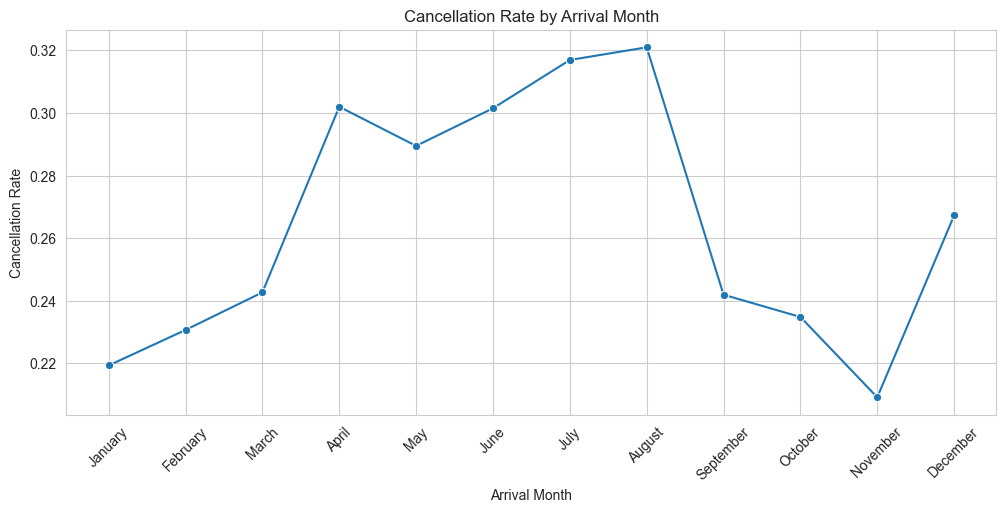

In [44]:
monthly_cancellation = (
    df.groupby('arrival_date_month')['is_canceled']
      .mean()
      .reindex(month_order)
      .reset_index()
)
plt.figure(figsize=(12, 5))
sns.lineplot(x='arrival_date_month', y='is_canceled', data=monthly_cancellation, marker='o')
plt.title('Cancellation Rate by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Cancellation Rate')
plt.xticks(rotation=45)
plt.show()

The cancellation rate is highest in July and August and lowest in November.

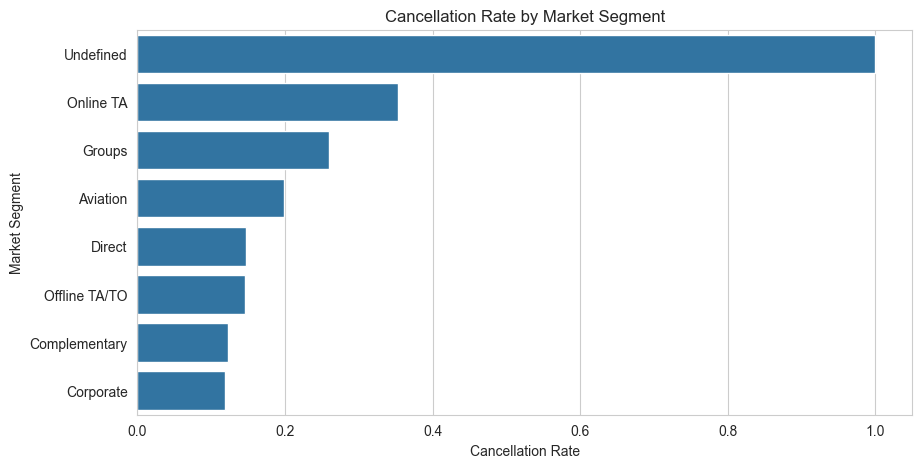

In [45]:
segment_cancellation = (
    df.groupby('market_segment')['is_canceled']
      .mean()
      .sort_values(ascending=False)
      .reset_index()
)
plt.figure(figsize=(10, 5))
sns.barplot(x='is_canceled', y='market_segment', data=segment_cancellation)
plt.title('Cancellation Rate by Market Segment')
plt.xlabel('Cancellation Rate')
plt.ylabel('Market Segment')
plt.show()

Online TA is the largest segment and has a higher cancellation rate than the other major market segments.

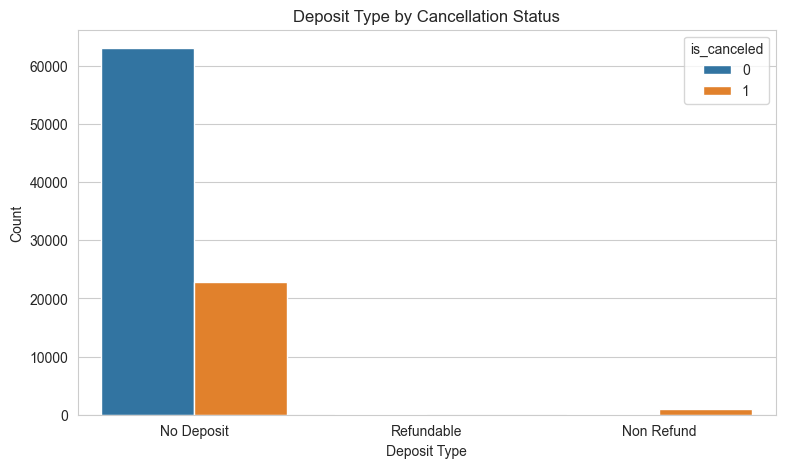

In [46]:
plt.figure(figsize=(9, 5))
sns.countplot(x='deposit_type', hue='is_canceled', data=df)
plt.title('Deposit Type by Cancellation Status')
plt.xlabel('Deposit Type')
plt.ylabel('Count')
plt.show()

Non-refundable bookings have an unusually high cancellation rate, while most bookings have no deposit.

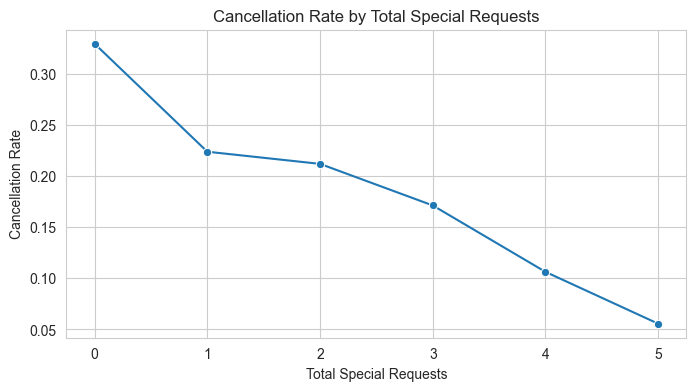

In [47]:
requests_cancellation = (
    df.groupby('total_of_special_requests')['is_canceled']
      .mean()
      .reset_index()
)
plt.figure(figsize=(8, 4))
sns.lineplot(x='total_of_special_requests', y='is_canceled', data=requests_cancellation, marker='o')
plt.title('Cancellation Rate by Total Special Requests')
plt.xlabel('Total Special Requests')
plt.ylabel('Cancellation Rate')
plt.show()

The cancellation rate decreases as the number of special requests increases.

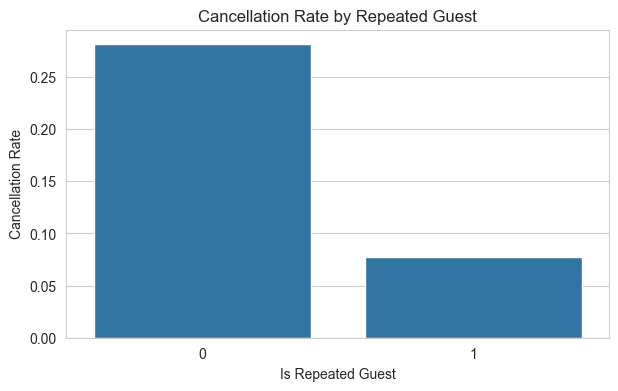

In [48]:
repeat_cancellation = (
    df.groupby('is_repeated_guest')['is_canceled']
      .mean()
      .reset_index()
)
plt.figure(figsize=(7, 4))
sns.barplot(x='is_repeated_guest', y='is_canceled', data=repeat_cancellation)
plt.title('Cancellation Rate by Repeated Guest')
plt.xlabel('Is Repeated Guest')
plt.ylabel('Cancellation Rate')
plt.show()

Repeated guests have a much lower cancellation rate than new guests.

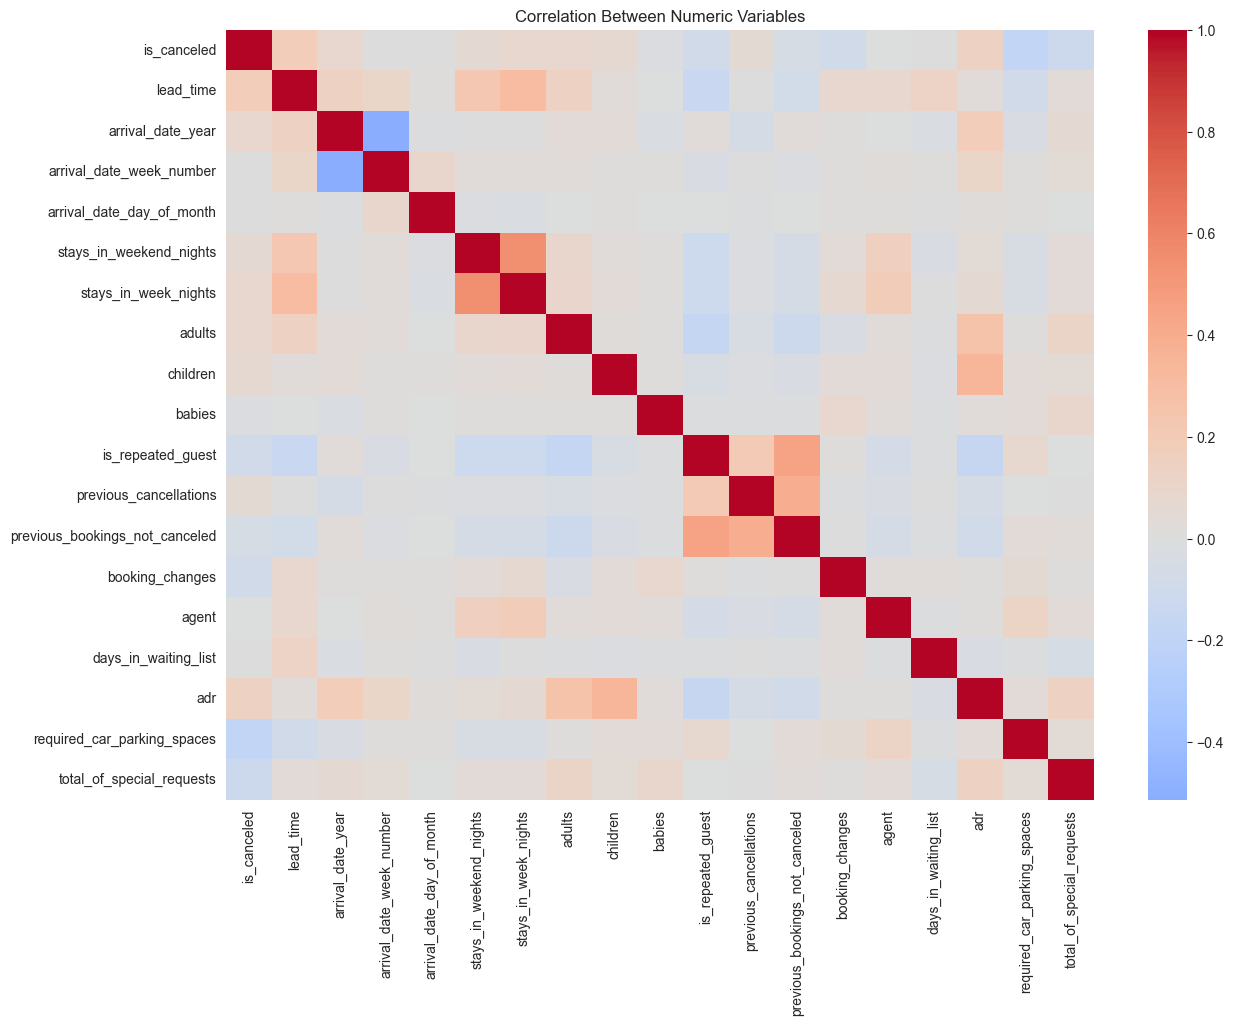

In [49]:
numeric_corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(14, 10))
sns.heatmap(numeric_corr, cmap='coolwarm', center=0)
plt.title('Correlation Between Numeric Variables')
plt.show()

In [50]:
numeric_corr['is_canceled'].sort_values(ascending=False)

is_canceled                       1.000000
lead_time                         0.182423
adr                               0.134133
arrival_date_year                 0.089053
stays_in_week_nights              0.084595
adults                            0.080703
children                          0.068240
stays_in_weekend_nights           0.061251
previous_cancellations            0.050927
arrival_date_day_of_month         0.005237
days_in_waiting_list              0.001843
arrival_date_week_number          0.001436
agent                            -0.000903
babies                           -0.020262
previous_bookings_not_canceled   -0.051881
is_repeated_guest                -0.088271
booking_changes                  -0.092336
total_of_special_requests        -0.118871
required_car_parking_spaces      -0.183818
Name: is_canceled, dtype: float64

The correlation view is a screening aid rather than a causal conclusion. Lead time and previous cancellations show positive relationships with cancellation, while repeated-guest history, parking requests, booking changes, and special requests show negative relationships; nonlinear models can capture patterns that simple pairwise correlation misses.

# Feature Engineering

In [51]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']

`total_nights` represents the complete length of stay, while `total_guests` represents the total number of guests in each booking.

# Prepare the Modeling Data

In [53]:
model_features = [
    'hotel', 'lead_time', 'arrival_date_year',
    'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies', 'meal',
    'market_segment', 'distribution_channel',
    'is_repeated_guest', 'previous_bookings_not_canceled',
    'booking_changes', 'deposit_type', 'customer_type',
    'adr', 'required_car_parking_spaces',
    'total_of_special_requests', 'total_nights', 'total_guests'
]

X = df[model_features]
y = df['is_canceled']

Only information available through the deployment form is used. The raw data is split before encoding or feature selection so the test set does not influence preprocessing.

In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_development, X_validation, y_development, y_validation = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

X_train.shape, X_test.shape, X_development.shape, X_validation.shape

((69554, 21), (17389, 21), (55643, 21), (13911, 21))

In [55]:
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()
numeric_cols = [col for col in model_features if col not in categorical_cols]
categorical_cols, numeric_cols

(['hotel',
  'meal',
  'market_segment',
  'distribution_channel',
  'deposit_type',
  'customer_type'],
 ['lead_time',
  'arrival_date_year',
  'stays_in_weekend_nights',
  'stays_in_week_nights',
  'adults',
  'children',
  'babies',
  'is_repeated_guest',
  'previous_bookings_not_canceled',
  'booking_changes',
  'adr',
  'required_car_parking_spaces',
  'total_of_special_requests',
  'total_nights',
  'total_guests'])

# Leakage-Safe Preprocessing and Feature Selection

`OneHotEncoder` and `SelectKBest` are placed inside each model pipeline. During cross-validation, every fold learns its categories and selected features only from that fold's training portion. This prevents validation-fold information from influencing preprocessing or feature selection.

In [56]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ('numeric', 'passthrough', numeric_cols),
    ('categorical', OneHotEncoder(
        handle_unknown='ignore',
        drop='first',
        sparse_output=False
    ), categorical_cols)
])

In [57]:
def build_pipeline(model):
    return Pipeline([
        ('preprocessor', preprocessor),
        ('selector', SelectKBest(score_func=f_classif, k=25)),
        ('scaler', StandardScaler()),
        ('model', model)
    ])

# Model Comparison

Thirteen classifiers are compared using stratified 3-fold cross-validation. The full preprocessing and selection pipeline is refitted independently inside every fold. Accuracy, precision, recall, F1-score, and ROC-AUC are reported because accuracy alone can hide poor cancellation detection.

In [58]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    AdaBoostClassifier, GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from xgboost import XGBClassifier

In [59]:
models = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'SGD Classifier': SGDClassifier(loss='log_loss', class_weight='balanced', max_iter=2000, random_state=42),
    'Linear SVC': LinearSVC(class_weight='balanced', random_state=42),
    'Gaussian NB': GaussianNB(),
    'KNN': KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
    'Decision Tree': DecisionTreeClassifier(max_depth=15, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', random_state=42, n_jobs=1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=1),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.08, max_depth=3, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_iter=100, learning_rate=0.08, max_leaf_nodes=31, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.08, subsample=0.85, colsample_bytree=0.85, eval_metric='logloss', random_state=42, n_jobs=1)
}

In [60]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {
    'accuracy': 'accuracy', 'precision': 'precision',
    'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'
}

model_results = []
for name, model in models.items():
    scores = cross_validate(
        build_pipeline(model), X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=1
    )
    model_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1': scores['test_f1'].mean(),
        'ROC-AUC': scores['test_roc_auc'].mean()
    })

In [61]:
results_df = (
    pd.DataFrame(model_results)
      .sort_values(['F1', 'ROC-AUC'], ascending=False)
      .reset_index(drop=True)
)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree,0.725925,0.498824,0.708548,0.585446,0.775779
1,XGBoost,0.801924,0.704686,0.473155,0.566160,0.830593
2,Logistic Regression,0.688400,0.456606,0.740552,0.564898,0.784814
3,Linear SVC,0.684907,0.453167,0.742973,0.562957,0.784779
4,Hist Gradient Boosting,0.800788,0.704669,0.465944,0.560960,0.829075
5,SGD Classifier,0.690657,0.458415,0.719076,0.559636,0.777932
6,Random Forest,0.786784,0.648357,0.479367,0.551197,0.810952
7,Extra Trees,0.773759,0.604227,0.497737,0.545835,0.787841
8,KNN,0.778647,0.626103,0.470787,0.537446,0.776796
9,Gradient Boosting,0.794246,0.700836,0.430835,0.533586,0.814783


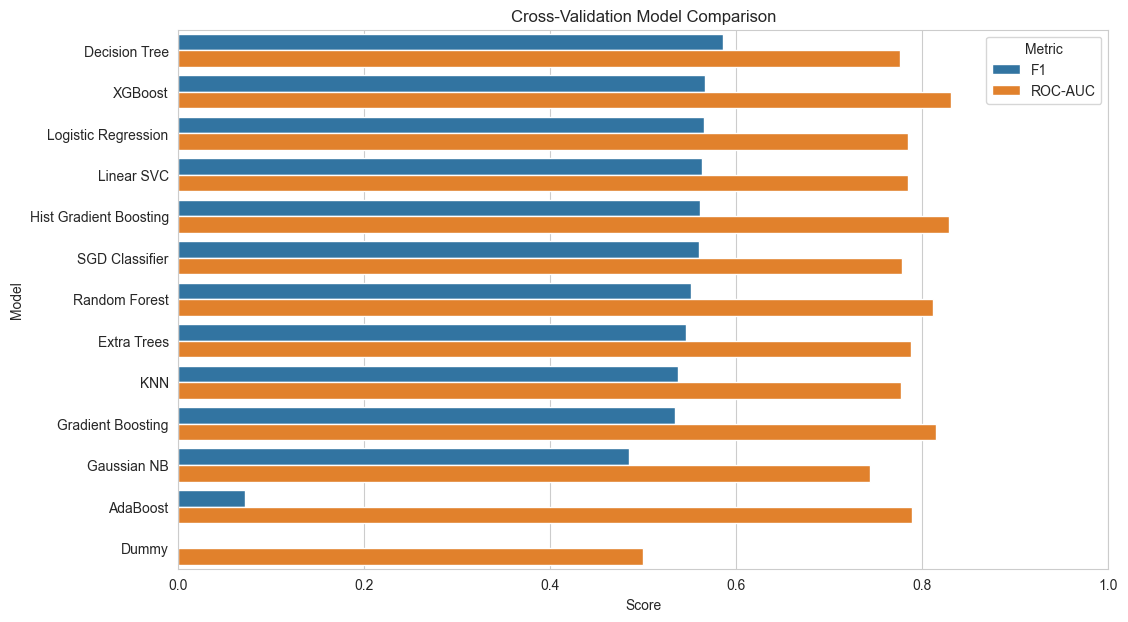

In [62]:
plot_results = results_df.melt(
    id_vars='Model', value_vars=['F1', 'ROC-AUC'],
    var_name='Metric', value_name='Score'
)
plt.figure(figsize=(12, 7))
sns.barplot(x='Score', y='Model', hue='Metric', data=plot_results)
plt.title('Cross-Validation Model Comparison')
plt.xlim(0, 1)
plt.show()

The Decision Tree has the highest initial cross-validation F1-score. XGBoost is selected for further tuning because it has the strongest cross-validation ROC-AUC while maintaining competitive F1 performance. The test set is not used for this decision.

# Hyperparameter Tuning

`GridSearchCV` tunes important XGBoost parameters using the development portion of the training data, with F1-score as the optimization metric. Preprocessing and feature selection remain inside every tuning fold. The separate validation portion is reserved for calibration assessment and threshold selection.

In [63]:
from sklearn.model_selection import GridSearchCV

xgb_pipeline = build_pipeline(XGBClassifier(
    n_estimators=333, learning_rate=0.07829368235538216,
    colsample_bytree=0.8067241076005821,
    gamma=0.22115723562853118,
    reg_lambda=0.2987274199563841,
    subsample=0.9048757220141508,
    eval_metric='logloss', random_state=42, n_jobs=1
))

xgb_params = {
    'model__max_depth': [5, 7, 9],
    'model__min_child_weight': [1, 3]
}

xgb_search = GridSearchCV(
    xgb_pipeline, xgb_params, scoring='f1', cv=cv, n_jobs=1
)
xgb_search.fit(X_development, y_development)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [5, 7, ...], 'model__min_child_weight': [1, 3]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;-

In [64]:
xgb_search.best_score_, xgb_search.best_params_

(0.576178776421127, {'model__max_depth': 9, 'model__min_child_weight': 3})

In [65]:
best_pipeline = xgb_search.best_estimator_
feature_names = best_pipeline.named_steps['preprocessor'].get_feature_names_out()
selected_mask = best_pipeline.named_steps['selector'].get_support()
selected_features = feature_names[selected_mask].tolist()
selected_features

['numeric__lead_time',
 'numeric__arrival_date_year',
 'numeric__stays_in_weekend_nights',
 'numeric__stays_in_week_nights',
 'numeric__adults',
 'numeric__children',
 'numeric__is_repeated_guest',
 'numeric__previous_bookings_not_canceled',
 'numeric__booking_changes',
 'numeric__adr',
 'numeric__required_car_parking_spaces',
 'numeric__total_of_special_requests',
 'numeric__total_nights',
 'numeric__total_guests',
 'categorical__hotel_Resort Hotel',
 'categorical__meal_SC',
 'categorical__market_segment_Corporate',
 'categorical__market_segment_Direct',
 'categorical__market_segment_Offline TA/TO',
 'categorical__market_segment_Online TA',
 'categorical__distribution_channel_Direct',
 'categorical__distribution_channel_TA/TO',
 'categorical__deposit_type_Non Refund',
 'categorical__customer_type_Transient',
 'categorical__customer_type_Transient-Party']

# Probability Calibration and Decision Threshold

Raw boosting probabilities and sigmoid-calibrated probabilities are compared on the reserved validation portion of the training data using Brier score and calibration curves. The test set is not used to choose calibration or the decision threshold.

In [66]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, precision_recall_curve

raw_validation_probabilities = best_pipeline.predict_proba(X_validation)[:, 1]
raw_brier = brier_score_loss(y_validation, raw_validation_probabilities)

calibrated_candidate = CalibratedClassifierCV(
    best_pipeline, method='sigmoid', cv=3
)
calibrated_candidate.fit(X_development, y_development)
calibrated_validation_probabilities = calibrated_candidate.predict_proba(
    X_validation
)[:, 1]
calibrated_brier = brier_score_loss(
    y_validation, calibrated_validation_probabilities
)

pd.Series({
    'Raw XGBoost Validation Brier Score': raw_brier,
    'Calibrated XGBoost Validation Brier Score': calibrated_brier
})

Raw XGBoost Validation Brier Score           0.139140
Calibrated XGBoost Validation Brier Score    0.139513
dtype: float64

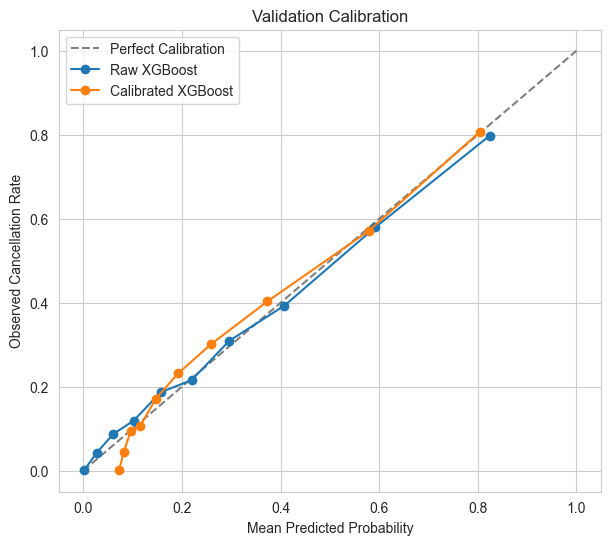

In [67]:
raw_true, raw_pred = calibration_curve(
    y_validation, raw_validation_probabilities, n_bins=10, strategy='quantile'
)
cal_true, cal_pred = calibration_curve(
    y_validation, calibrated_validation_probabilities,
    n_bins=10, strategy='quantile'
)
plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfect Calibration')
plt.plot(raw_pred, raw_true, marker='o', label='Raw XGBoost')
plt.plot(cal_pred, cal_true, marker='o', label='Calibrated XGBoost')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Cancellation Rate')
plt.title('Validation Calibration')
plt.legend()
plt.show()

In [68]:
if calibrated_brier < raw_brier:
    final_pipeline = calibrated_candidate
    threshold_probabilities = calibrated_validation_probabilities
    probability_model = 'Calibrated XGBoost'
else:
    final_pipeline = best_pipeline
    threshold_probabilities = raw_validation_probabilities
    probability_model = 'Raw XGBoost'

threshold_precision, threshold_recall, thresholds = precision_recall_curve(
    y_validation, threshold_probabilities
)
threshold_f1 = (
    2 * threshold_precision * threshold_recall
    / (threshold_precision + threshold_recall + 1e-12)
)
best_threshold = float(thresholds[np.argmax(threshold_f1[:-1])])
probability_model, best_threshold

('Raw XGBoost', 0.30294501781463623)

# Final Untouched Test Evaluation

The finalized pipeline and threshold are now evaluated once on the untouched test set. These test results report final generalization performance; they are not used to choose the model.

In [69]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, brier_score_loss,
    ConfusionMatrixDisplay, RocCurveDisplay
)

final_pipeline.fit(X_train, y_train)
test_probabilities = final_pipeline.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

In [70]:
final_metrics = pd.Series({
    'Accuracy': accuracy_score(y_test, test_predictions),
    'Precision': precision_score(y_test, test_predictions),
    'Recall': recall_score(y_test, test_predictions),
    'F1': f1_score(y_test, test_predictions),
    'ROC-AUC': roc_auc_score(y_test, test_probabilities),
    'Brier Score': brier_score_loss(y_test, test_probabilities)
})
final_metrics

Accuracy       0.775375
Precision      0.571989
Recall         0.705895
F1             0.631926
ROC-AUC        0.840660
Brier Score    0.135854
dtype: float64

In [71]:
print(classification_report(y_test, test_predictions, digits=4))

              precision    recall  f1-score   support

           0     0.8788    0.8015    0.8384     12639
           1     0.5720    0.7059    0.6319      4750

    accuracy                         0.7754     17389
   macro avg     0.7254    0.7537    0.7351     17389
weighted avg     0.7950    0.7754    0.7820     17389



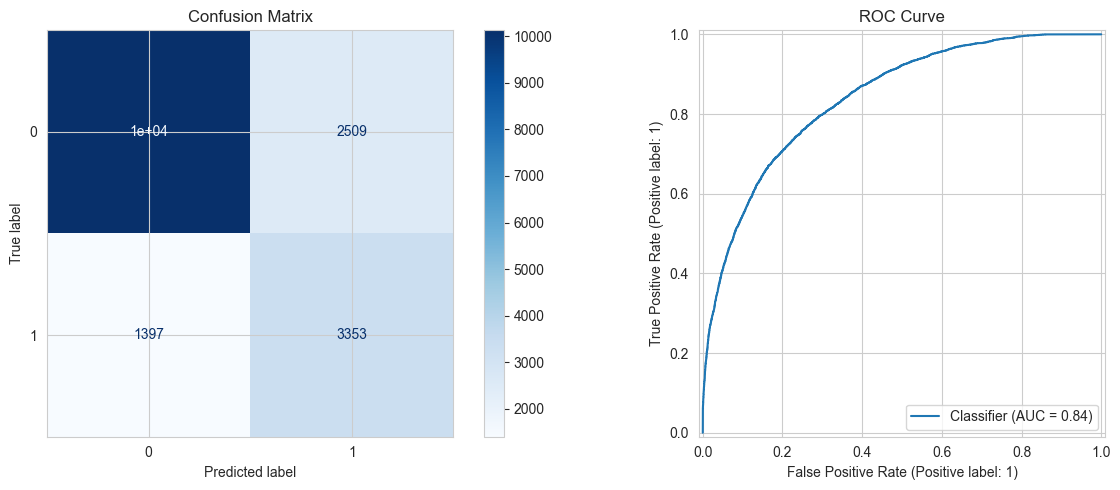

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, cmap='Blues', ax=ax[0]
)
ax[0].set_title('Confusion Matrix')
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=ax[1])
ax[1].set_title('ROC Curve')
plt.tight_layout()
plt.show()

XGBoost was selected for further tuning because it achieved the highest cross-validation ROC-AUC while maintaining competitive F1 performance. Hyperparameters were tuned on development data, while calibration and the decision threshold were selected on reserved validation data. Calibration did not improve validation Brier score, so raw XGBoost probabilities were retained. The finalized pipeline was then evaluated once on the untouched test set.

# Save the Deployment Pipeline

In [73]:
import pickle

pickle.dump(final_pipeline, open('../models/pipeline.pkl', 'wb'))
pickle.dump(best_threshold, open('../models/threshold.pkl', 'wb'))